# Chapter 2: Pre-Model Workflow and Data Preprocessing
**Book:** *scikit-learn Cookbook, Third Edition* — John Sukup

## Learning objectives
- Explain why raw-data quality affects model performance.
- Handle missing numerical and categorical values.
- Compare common feature-scaling techniques.
- Encode categorical variables appropriately.
- Build preprocessing and modeling workflows with `Pipeline` and `ColumnTransformer`.
- Create useful features and evaluate a complete workflow without data leakage.

> This notebook follows the chapter's main topics using small, reproducible examples. Run cells in order.

## 1. Imports and reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler,
    OneHotEncoder, OrdinalEncoder, PolynomialFeatures
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import make_classification

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

NumPy: 2.3.5
pandas: 2.2.3


## 2. Why raw-data quality matters

Models learn patterns from the examples they receive. Missing values, unusual outliers, inconsistent categories, and features on very different scales can affect the patterns a model learns.

Common issues covered in this chapter:
- **Missing data:** values are absent or unknown.
- **Outliers:** observations far from the bulk of the data; investigate whether they are errors or meaningful rare events.
- **Categorical variables:** text categories often need encoding before many estimators can use them.
- **Feature scale:** some algorithms, particularly distance-based methods, are sensitive to feature magnitudes.
- **Data leakage:** information from the test set influences training or preprocessing, making evaluation overly optimistic.

In [2]:
raw = pd.DataFrame({
    "age": [21, 25, np.nan, 35, 42, 29, 120, 31],
    "monthly_spend": [250, 320, 280, np.nan, 500, 310, 450, 295],
    "plan": ["Basic", "Plus", "Basic", "Pro", "Plus", None, "Pro", "Basic"],
    "renewed": [0, 1, 0, 1, 1, 0, 1, 0]
})

display(raw)
print("\nMissing values per column:")
display(raw.isna().sum().to_frame("missing_count"))

,age,monthly_spend,plan,renewed
0,21.0,250.0,Basic,0
1,25.0,320.0,Plus,1
2,NaN,280.0,Basic,0
3,35.0,NaN,Pro,1
4,42.0,500.0,Plus,1
5,29.0,310.0,None,0
6,120.0,450.0,Pro,1
7,31.0,295.0,Basic,0



Missing values per column:


,missing_count
age,1
monthly_spend,1
plan,1
renewed,0


The value `120` in `age` is worth investigating, but it should not automatically be deleted. Domain knowledge determines whether a value is erroneous or a valid rare observation.

## 3. Handling missing values

`SimpleImputer` replaces missing values using a chosen strategy, such as the mean, median, most frequent value, or a constant. The median is often a reasonable baseline for numerical data when extreme values may skew the mean. Categorical columns can use the most frequent value or a constant category such as `"Unknown"`.

Fit imputers on the training data only; use the fitted imputer to transform validation, test, and future data.

In [3]:
numeric_features = ["age", "monthly_spend"]
categorical_features = ["plan"]

X = raw[numeric_features + categorical_features]
y = raw["renewed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_num = numeric_imputer.fit_transform(X_train[numeric_features])
X_test_num = numeric_imputer.transform(X_test[numeric_features])

X_train_cat = categorical_imputer.fit_transform(X_train[categorical_features])
X_test_cat = categorical_imputer.transform(X_test[categorical_features])

print("Missing numeric values after imputation:", np.isnan(X_train_num).sum())
print("Training numeric medians:", numeric_imputer.statistics_)
print("Most frequent category:", categorical_imputer.statistics_)

Missing numeric values after imputation: 0
Training numeric medians: [ 31. 295.]
Most frequent category: ['Basic']


### Alternative: K-nearest-neighbor imputation

`KNNImputer` estimates a missing value using nearby rows. It can use relationships among features, but may be more computationally expensive and is sensitive to feature scales. For this reason, a simple imputer is often a useful baseline.

In [4]:
knn_imputer = KNNImputer(n_neighbors=2)
knn_example = pd.DataFrame({
    "hours_studied": [2.0, 4.0, np.nan, 8.0],
    "practice_tests": [1.0, 3.0, 4.0, np.nan]
})

display(knn_example)
display(pd.DataFrame(
    knn_imputer.fit_transform(knn_example),
    columns=knn_example.columns
).round(2))

,hours_studied,practice_tests
0,2.0,1.0
1,4.0,3.0
2,NaN,4.0
3,8.0,NaN


,hours_studied,practice_tests
0,2.0,1.0
1,4.0,3.0
2,3.0,4.0
3,8.0,2.0


## 4. Feature scaling

Scaling changes the numeric range or distribution of features. It is especially important for methods that use distances or optimization, such as K-nearest neighbors and support vector machines. Tree-based models generally do not require feature scaling.

- **StandardScaler:** centers features around mean 0 and scales to standard deviation 1.
- **MinMaxScaler:** maps each feature to a chosen range, usually 0–1.
- **RobustScaler:** uses the median and interquartile range, making it less affected by outliers than mean/standard-deviation scaling.

For standardization, the transformation is \(z = (x - \mu) / \sigma\), where the mean and standard deviation are learned from training data.

In [5]:
scale_data = pd.DataFrame({
    "small_range": [1, 2, 3, 4, 5, 6],
    "large_range": [100, 200, 300, 400, 500, 600],
    "with_outlier": [10, 11, 12, 13, 14, 100]
})
display(scale_data)

,small_range,large_range,with_outlier
0,1,100,10
1,2,200,11
2,3,300,12
3,4,400,13
4,5,500,14
5,6,600,100


In [6]:
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

scaled_results = {}
for name, scaler in scalers.items():
    scaled_results[name] = pd.DataFrame(
        scaler.fit_transform(scale_data),
        columns=scale_data.columns
    )

for name, result in scaled_results.items():
    print(name)
    display(result.round(2))

StandardScaler


,small_range,large_range,with_outlier
0,-1.46,-1.46,-0.51
1,-0.88,-0.88,-0.48
2,-0.29,-0.29,-0.45
3,0.29,0.29,-0.42
4,0.88,0.88,-0.39
5,1.46,1.46,2.23


MinMaxScaler


,small_range,large_range,with_outlier
0,0.0,0.0,0.00
1,0.2,0.2,0.01
2,0.4,0.4,0.02
3,0.6,0.6,0.03
4,0.8,0.8,0.04
5,1.0,1.0,1.00


RobustScaler


,small_range,large_range,with_outlier
0,-1.0,-1.0,-1.0
1,-0.6,-0.6,-0.6
2,-0.2,-0.2,-0.2
3,0.2,0.2,0.2
4,0.6,0.6,0.6
5,1.0,1.0,35.0


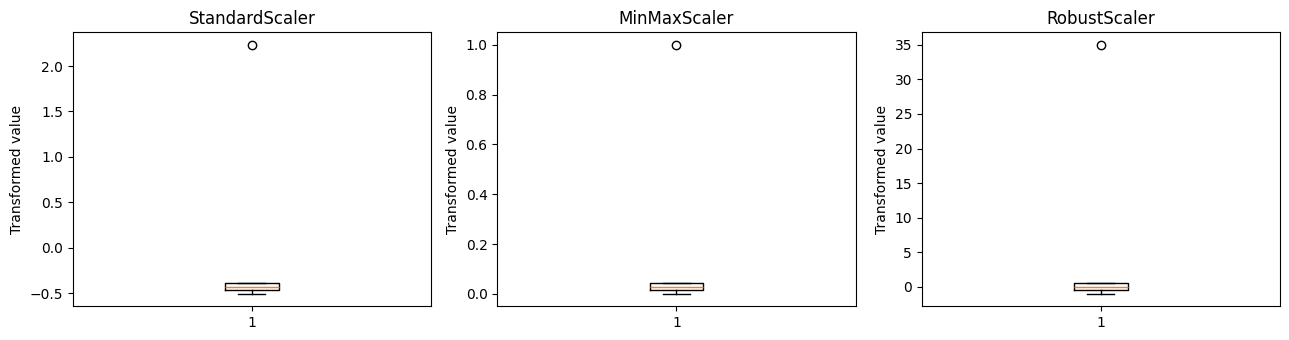

In [7]:
# Visualize how the scalers transform the feature containing an outlier.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, result) in zip(axes, scaled_results.items()):
    ax.boxplot(result["with_outlier"])
    ax.set_title(name)
    ax.set_ylabel("Transformed value")
plt.tight_layout()
plt.show()

**Interpretation:** scaling puts features onto more comparable scales, but the best choice depends on the data and estimator. `RobustScaler` is less influenced by the extreme value in this example. Scaling does not fix an invalid outlier; investigate the data itself as well.

## 5. Encoding categorical variables

Categorical features are commonly **nominal** (no natural order, such as color or plan type) or **ordinal** (a meaningful order, such as low, medium, high).

- Use `OneHotEncoder` for nominal categories so the model does not interpret arbitrary integer codes as an order.
- Use `OrdinalEncoder` when category order is meaningful and should be represented as ordered numbers.
- `handle_unknown="ignore"` lets a one-hot encoder handle categories not seen during fitting.

In [8]:
categories = pd.DataFrame({
    "plan": ["Basic", "Plus", "Pro", "Basic", "Pro"],
    "satisfaction": ["Low", "Medium", "High", "Medium", "High"]
})
display(categories)

,plan,satisfaction
0,Basic,Low
1,Plus,Medium
2,Pro,High
3,Basic,Medium
4,Pro,High


In [9]:
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
plan_encoded = onehot.fit_transform(categories[["plan"]])
plan_encoded_df = pd.DataFrame(
    plan_encoded,
    columns=onehot.get_feature_names_out(["plan"])
)
display(plan_encoded_df)

,plan_Basic,plan_Plus,plan_Pro
0,1.0,0.0,0.0
1,0.0,1.0,0.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0


In [10]:
ordinal = OrdinalEncoder(
    categories=[["Low", "Medium", "High"]]
)
satisfaction_encoded = ordinal.fit_transform(categories[["satisfaction"]])
display(pd.DataFrame({
    "satisfaction": categories["satisfaction"],
    "encoded": satisfaction_encoded.ravel().astype(int)
}))

,satisfaction,encoded
0,Low,0
1,Medium,1
2,High,2
3,Medium,1
4,High,2


**Important:** integer-encoding nominal categories can accidentally imply a ranking that does not exist. Also, encoding a target label is different from encoding input features; here, `OrdinalEncoder` is applied to an ordered input feature.

## 6. Combine preprocessing with `ColumnTransformer` and `Pipeline`

Real datasets often mix numerical and categorical columns. `ColumnTransformer` applies the appropriate transformation to each subset of columns, while `Pipeline` chains preprocessing and the final estimator.

This helps keep the workflow consistent between training and prediction and reduces leakage risk because preprocessing is fitted within each training fold.

In [11]:
# Make the toy dataset a little larger so the train/test example is meaningful.
rng = np.random.default_rng(RANDOM_STATE)
n = 240

df = pd.DataFrame({
    "age": rng.normal(35, 10, n).clip(18, 75),
    "monthly_spend": rng.normal(350, 100, n).clip(50, 900),
    "visits_last_month": rng.poisson(4, n),
    "plan": rng.choice(["Basic", "Plus", "Pro"], n, p=[0.5, 0.3, 0.2])
})
# Create a target with a signal from spend and visits, plus noise.
logit = (
    -2.0
    + 0.004 * df["monthly_spend"]
    + 0.25 * df["visits_last_month"]
    + 0.012 * (df["age"] - 35)
    + 0.5 * (df["plan"] == "Pro")
)
probability = 1 / (1 + np.exp(-logit))
df["renewed"] = rng.binomial(1, probability)

# Add a few missing values to demonstrate preprocessing in the pipeline.
for col in ["age", "monthly_spend", "plan"]:
    missing_rows = rng.choice(df.index, size=8, replace=False)
    df.loc[missing_rows, col] = np.nan

display(df.head())
print("Missing values:")
display(df.isna().sum().to_frame("count"))

,age,monthly_spend,visits_last_month,plan,renewed
0,38.047171,262.313922,8,Basic,1
1,24.600159,340.573745,2,NaN,0
2,42.504512,174.227161,2,Plus,0
3,44.405647,203.295475,2,Plus,1
4,18.000000,562.924711,1,Plus,1


Missing values:


,count
age,8
monthly_spend,8
visits_last_month,0
plan,8
renewed,0


In [12]:
X = df.drop(columns="renewed")
y = df["renewed"]

numeric_features = ["age", "monthly_spend", "visits_last_month"]
categorical_features = ["plan"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))

Test accuracy: 0.650

Classification report:
              precision    recall  f1-score   support

           0       0.54      0.65      0.59        23
           1       0.75      0.65      0.70        37

    accuracy                           0.65        60
   macro avg       0.64      0.65      0.64        60
weighted avg       0.67      0.65      0.65        60



### Inspect the transformed feature matrix

In [13]:
fitted_preprocessor = model.named_steps["preprocessing"]
X_train_transformed = fitted_preprocessor.transform(X_train)
feature_names = fitted_preprocessor.get_feature_names_out()

print("Transformed training shape:", X_train_transformed.shape)
print("Feature names:")
print(feature_names.tolist())

Transformed training shape: (180, 6)
Feature names:
['numeric__age', 'numeric__monthly_spend', 'numeric__visits_last_month', 'categorical__plan_Basic', 'categorical__plan_Plus', 'categorical__plan_Pro']


### Data leakage: what to avoid

Do **not** impute or scale the entire dataset before splitting into training and test sets. That lets the test set influence preprocessing statistics. Instead, split first and put learned preprocessing steps inside a pipeline. During cross-validation, the pipeline is refitted on each fold's training portion.

## 7. Feature engineering

Feature engineering creates or transforms input variables to better represent patterns for a model. The appropriate transformation depends on the problem and should be evaluated rather than assumed to improve performance.

`PolynomialFeatures` can create interaction and polynomial terms from numerical features. For two input features \(x_1\) and \(x_2\), degree 2 can include \(x_1^2\), \(x_1x_2\), and \(x_2^2\).

In [14]:
small_X = pd.DataFrame({
    "study_hours": [1, 2, 3, 4],
    "practice_tests": [0, 1, 1, 2]
})

poly = PolynomialFeatures(degree=2, include_bias=False)
poly_values = poly.fit_transform(small_X)
poly_df = pd.DataFrame(
    poly_values,
    columns=poly.get_feature_names_out(small_X.columns)
)

display(small_X)
display(poly_df)

,study_hours,practice_tests
0,1,0
1,2,1
2,3,1
3,4,2


,study_hours,practice_tests,study_hours^2,study_hours practice_tests,practice_tests^2
0,1.0,0.0,1.0,0.0,0.0
1,2.0,1.0,4.0,2.0,1.0
2,3.0,1.0,9.0,3.0,1.0
3,4.0,2.0,16.0,8.0,4.0


Polynomial features can model some nonlinear relationships with a linear estimator, but they increase the number of features and may increase overfitting. Use them thoughtfully and evaluate on held-out data.

## 8. Practical exercise

Use the mixed-type dataset from Section 6 to complete these tasks:

1. Replace the numerical imputation strategy with `mean` and compare the test score.
2. Replace `StandardScaler` with `RobustScaler` and compare results.
3. Change the classifier to another suitable estimator and compare the result.
4. Explain why all preprocessing should be fitted only on the training data.

Keep the test set fixed when comparing these changes. Small score differences on a single split do not necessarily mean one workflow is universally better.

In [15]:
# Exercise scaffold: change one setting at a time.
exercise_numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", RobustScaler())
])

exercise_preprocessor = ColumnTransformer(transformers=[
    ("numeric", exercise_numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

exercise_model = Pipeline(steps=[
    ("preprocessing", exercise_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

exercise_model.fit(X_train, y_train)
exercise_predictions = exercise_model.predict(X_test)

print(f"Exercise model test accuracy: {accuracy_score(y_test, exercise_predictions):.3f}")

Exercise model test accuracy: 0.633


## Chapter summary

- Raw-data quality affects how well a model generalizes.
- Use imputers to handle missing values; choose strategies based on the feature and problem.
- Scaling is especially important for distance-based and many optimization-based estimators, but is not universally required.
- Choose categorical encoders according to whether categories are nominal or ordinal.
- `ColumnTransformer` handles different column types, and `Pipeline` keeps preprocessing and modeling together.
- Fit preprocessing on training data only to avoid data leakage.
- Feature engineering can create useful representations, but added complexity should be evaluated.

## References
- John Sukup, *scikit-learn Cookbook, Third Edition*, Chapter 2: “Pre-Model Workflow and Data Preprocessing.”
- Official companion repository: https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition